# Dataset preparation



## 1. 📥​ Imports

In [19]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "tcibench" / "preparation" / "metadata.json").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the tcibench project.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from tcibench.preparation import Dataset, load_dataset, load_metadata, plot_feature_distributions

In [24]:
RAW_ROOT = PROJECT_ROOT / "data" / "raw"

DATASET_PATHS = {
    "diabetes": RAW_ROOT / "diabetes.csv",
    "sick": RAW_ROOT / "sick.arff",
    "predictive_maintenance": RAW_ROOT / "predictive_maintenance.csv",
    "adult": RAW_ROOT / "adult.csv"
}

In [23]:
import pandas as pd
from pathlib import Path

# Adjust paths to your files
data_path = Path("/home/labian-3/Documentos/Fernanda/tcibench/data/raw/adult/adult.data")
test_path = Path("/home/labian-3/Documentos/Fernanda/tcibench/data/raw/adult/adult.test")
output_path = Path("/home/labian-3/Documentos/Fernanda/tcibench/data/raw/adult.csv")

columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income",
]

# Load the original training file
train = pd.read_csv(
    data_path,
    header=None,
    names=columns,
    skipinitialspace=True,
    na_values="?",
)

# Load the original test file, skipping its first metadata line
test = pd.read_csv(
    test_path,
    header=None,
    names=columns,
    skiprows=1,
    skipinitialspace=True,
    na_values="?",
)

# Normalize whitespace and income labels
for df in (train, test):
    for column in df.select_dtypes(include="object").columns:
        df[column] = df[column].str.strip()

    df["income"] = df["income"].str.rstrip(".")

# Combine both files
adult = pd.concat([train, test], ignore_index=True)

# Save the combined dataset
adult.to_csv(output_path, index=False)

print(f"Saved to: {output_path.resolve()}")
print(f"Shape: {adult.shape}")
print("\nClass distribution:")
print(adult["income"].value_counts(dropna=False))

Saved to: /home/labian-3/Documentos/Fernanda/tcibench/data/raw/adult.csv
Shape: (48842, 15)

Class distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


/tmp/ipykernel_701370/1120226852.py:48: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:
/tmp/ipykernel_701370/1120226852.py:48: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dt

## 2. ⚙️​​ Utils

In [25]:
def inspect_dataset(dataset_id: str):
    """Show metadata, cleaning, split, class balance, and feature distributions."""
    if dataset_id not in DATASET_PATHS:
        raise ValueError(f"Choose one of: {', '.join(DATASET_PATHS)}")

    metadata = load_metadata(dataset_id)
    raw = load_dataset(DATASET_PATHS[dataset_id])
    dataset = Dataset(raw, metadata)
    cleaned, cleaning_stats = dataset.preprocessing.clean(raw)
    folds = dataset.preprocessing.split(cleaned)
    train, test, split_audit = folds[0]

    print(f"{metadata.display_name} | target: {metadata.target_column}")
    display(pd.DataFrame(metadata.columns).T)
    print(f"Raw data: {raw.shape[0]} rows, {raw.shape[1]} columns")
    display(raw.head())

    print("Cleaning")
    display(pd.Series(cleaning_stats, name="value").to_frame())
    display(cleaned.head())

    print("Train/test split")
    display(pd.Series(split_audit, name="value").to_frame())
    target = metadata.target_column
    display(pd.DataFrame({
        "train_count": train[target].value_counts(),
        "train_proportion": train[target].value_counts(normalize=True),
        "test_count": test[target].value_counts(),
        "test_proportion": test[target].value_counts(normalize=True),
    }).fillna(0).sort_index())

    figure = plot_feature_distributions(cleaned, train, test, metadata)
    plt.show()
    plt.close(figure)
    return train, test

## 3. 🔎 Inspect a dataset

Adult Income | target: income


,type,description
age,numeric,Age in years.
workclass,categorical,Employment sector or type of employer.
fnlwgt,numeric,Final CPS sampling weight.
education,categorical,Highest education level category.
education-num,numeric,Numeric encoding of education.
marital-status,categorical,Marital status.
occupation,categorical,Occupation category.
relationship,categorical,Relationship role within the household.
race,categorical,Race category.
sex,categorical,Sex category (Female or Male).


Raw data: 48842 rows, 15 columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Cleaning


,value
original_rows,48842
cleaned_rows,45175
dropped_columns,[]
all_missing_columns,[]
missing_values_before_cleaning,6465
missing_values_by_column_before_cleaning,"{'workclass': 2799, 'occupation': 2809, 'nativ..."
removed_missing_rows,3620
removed_duplicate_rows,47
numeric_decimals,4
target_counts_before_cleaning,"{'<=50K': 37155, '>50K': 11687}"


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Train/test split


,value
fold,1
n_splits,5
split_seed,42
input_rows,45175
train_rows,36140
test_rows,9035
train_target_counts,"{'<=50K': 27178, '>50K': 8962}"
test_target_counts,"{'<=50K': 6795, '>50K': 2240}"
majority_class,<=50K
minority_class,>50K


,train_count,train_proportion,test_count,test_proportion
income,,,,
<=50K,27178,0.75202,6795,0.752075
>50K,8962,0.24798,2240,0.247925


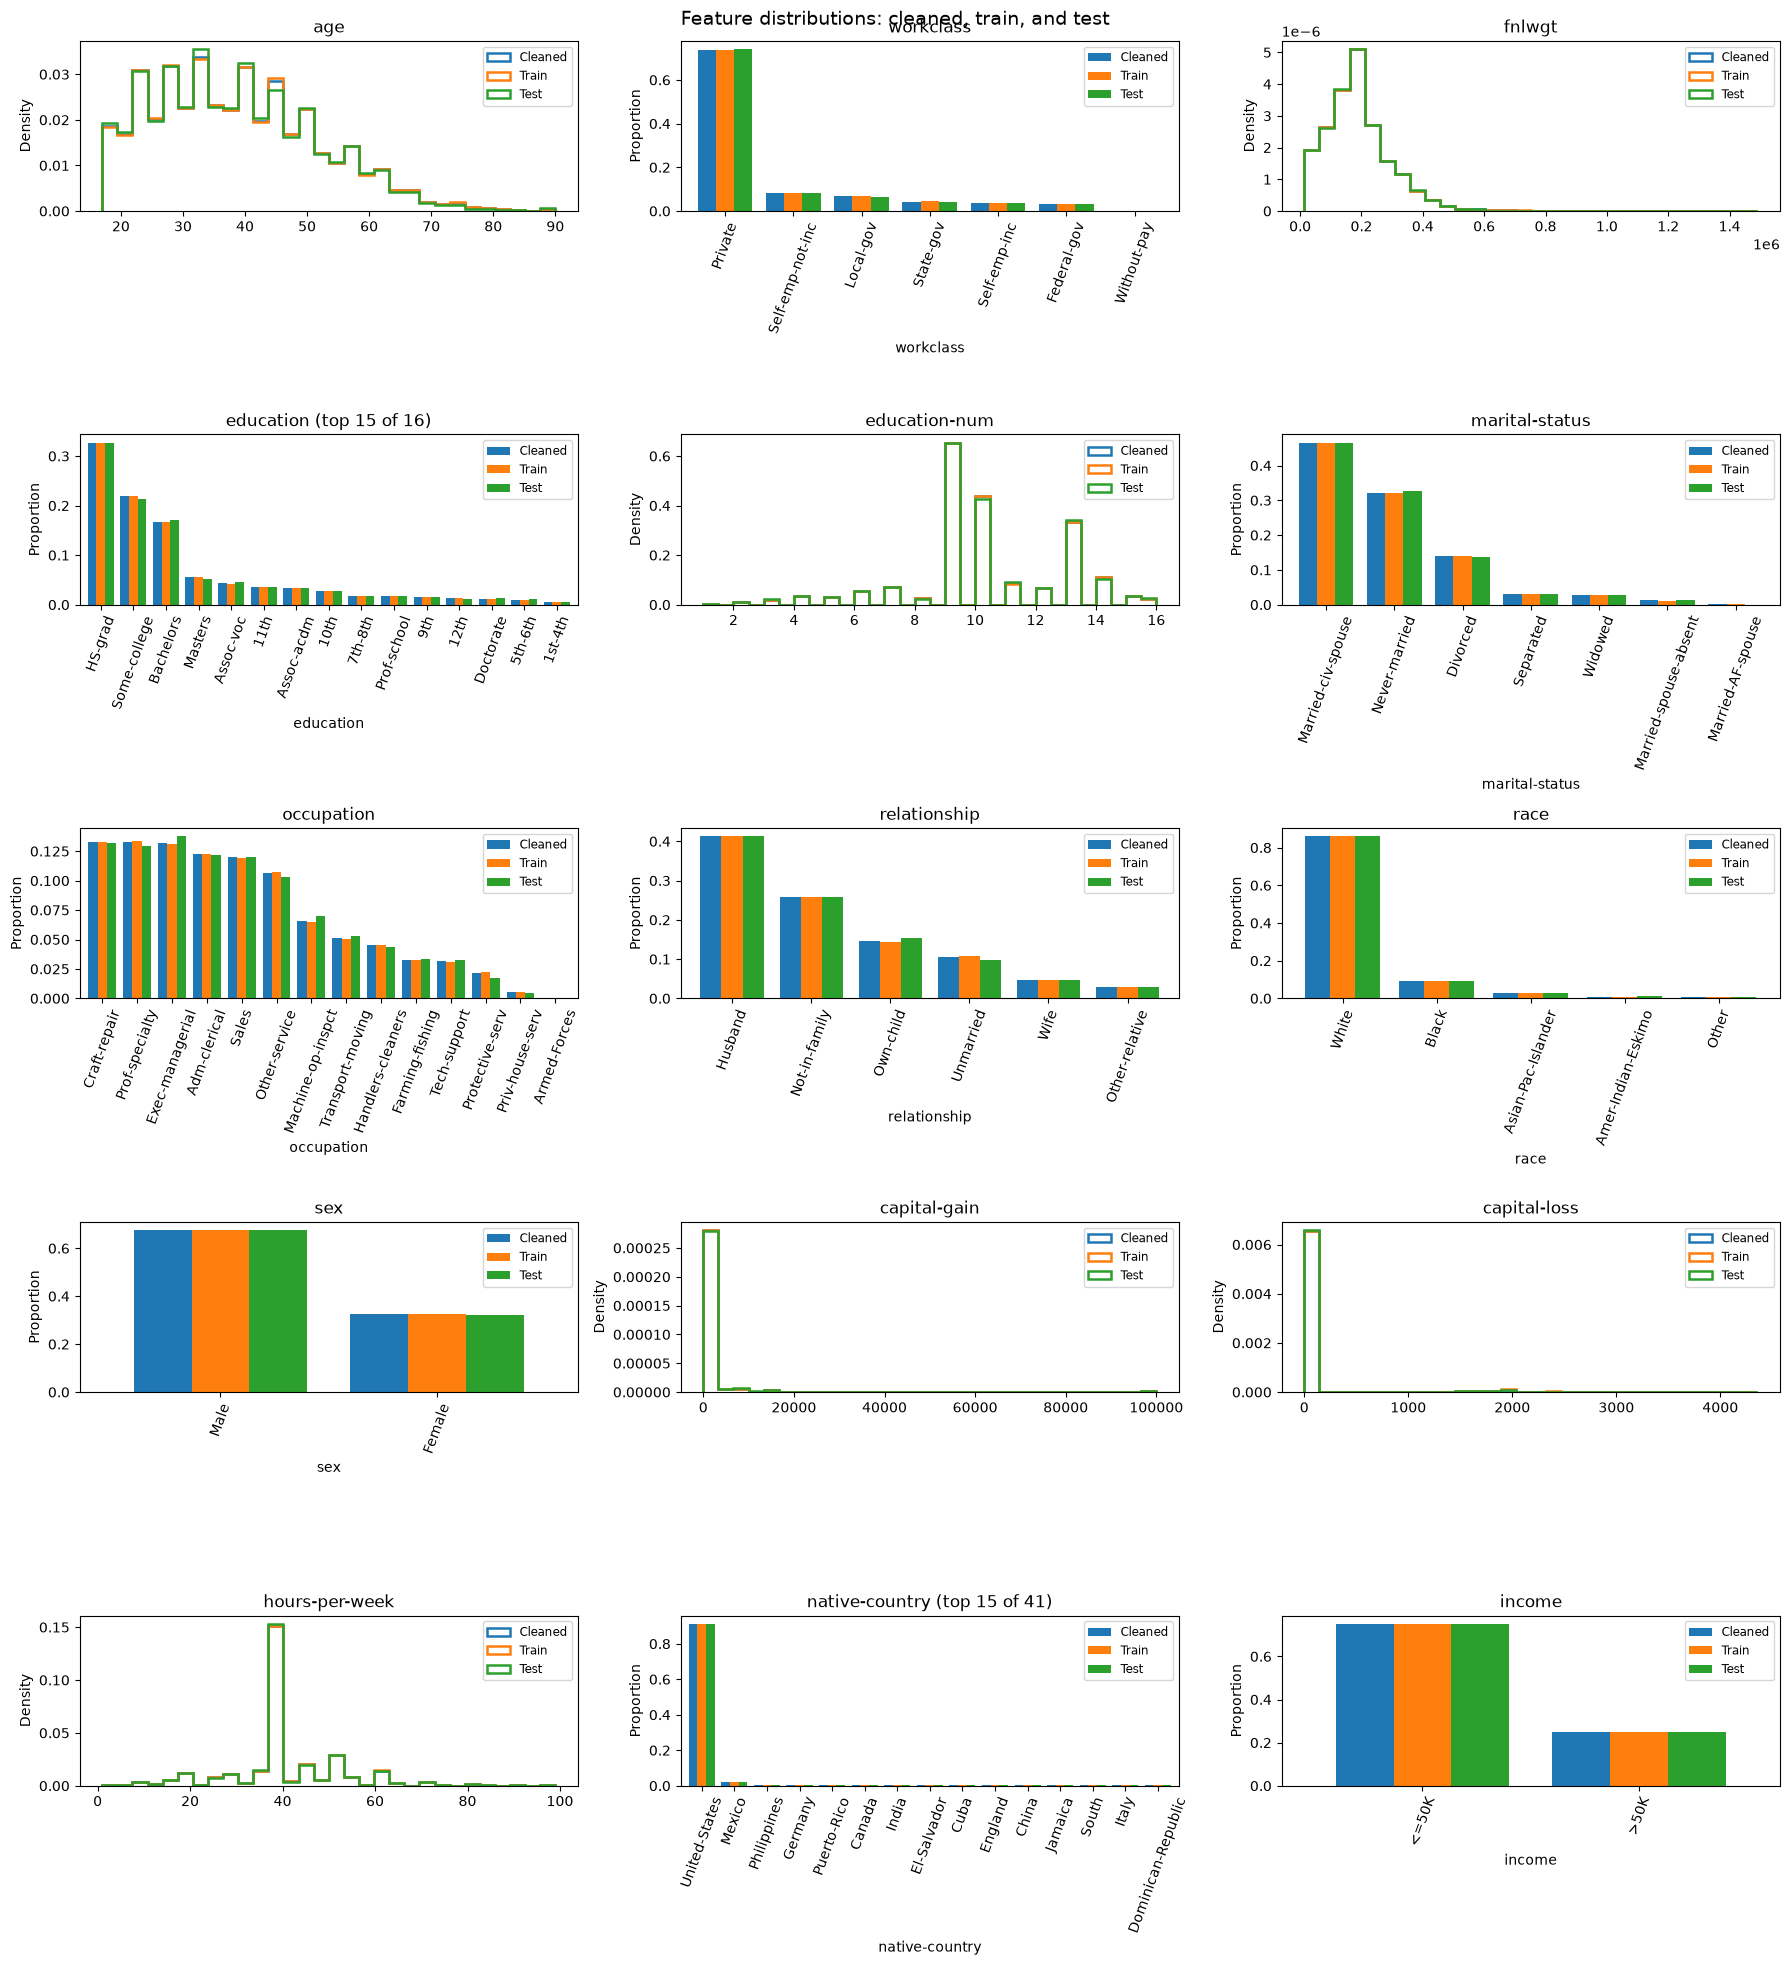

In [26]:
train, test = inspect_dataset("adult")